# EWELD C24 — Benchmark principale

Notebook principale del progetto. Il codice sta in tre librerie, accanto al notebook:

| File | Ruolo |
|---|---|
| `dati.py` | carica la serie oraria, divide train / validazione / test per date e costruisce le finestre. **Tutti i modelli ricevono gli stessi esempi.** |
| `modelli.py` | baseline, XGBoost, LightGBM, LSTM, GRU e i preaddestrati zero-shot (Chronos-2, Chronos-Bolt, TimesFM 2.5, TimesFM 3.0) con interfaccia comune (`addestra`, `prevedi_test`) e curva di loss. |
| `../metriche.py` | MAE, RMSE, sMAPE, MASE, Bias (file unico per tutti i benchmark, nella radice). **Tutti i modelli sono valutati con le stesse funzioni.** |

**Protocollo.** I modelli sono addestrati a prevedere 48 ore in un solo passo (strategia diretta multi-output).
Normalizzazione stimata solo sul train. La validazione serve per l'early stopping, il test viene usato una sola volta
e il modello non viene mai riaddestrato sul test.

**Quattro valutazioni dello stesso modello addestrato**, sullo stesso periodo di test:

| Valutazione | Origini | Cosa vede il modello | Ore valutate |
|---|---|---|---|
| **Diretta 48h** | ogni 48 ore | storico reale fino all'origine | +1…+48 |
| **Breve termine 6h** | ogni ora | storico reale fino all'ora precedente | +1…+6 |
| **One-step-ahead** | ogni ora | storico reale fino all'ora precedente | solo +1 |
| **Autoregressiva 48h** | ogni 48 ore | storico reale fino all'origine; poi le **proprie** previsioni, reinserite ora per ora | +1…+48 |

Le metriche sono calcolate su tutte le ore di test insieme. Per la diretta e il breve termine si riportano anche
i tagli dell'orizzonte (metriche sulle sole prime ore di ogni origine).

**Modelli preaddestrati (zero-shot).** Chronos e TimesFM non vengono addestrati sui dati EWELD: ricevono solo lo storico
del consumo (default 2048 ore, circa 12 settimane, senza calendario) e prevedono direttamente. Girano nei propri venv
(`.venv_chronos`, `.venv_timesfm`) con i pesi già in locale. Stesse origini, stessi target e stesse metriche degli altri modelli.

## 0. Configurazione

In [1]:
import sys
import time
import json
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

sys.path.append(str(Path.cwd().parent))   # metriche.py, unico per tutti i benchmark, sta nella radice
import dati
import modelli
import metriche

UTENTE = 'U141'                      # disponibili: dati.utenti_disponibili()
PERIODI = {                          # date incluse
    'train':       ('2018-11-01', '2019-09-30'),
    'validazione': ('2019-10-01', '2019-10-31'),
    'test':        ('2019-11-01', '2019-12-31'),
}
HORIZON = 48                         # ore previste a ogni origine
ORE_BREVE = 6                        # breve termine: ore previste a ogni origine oraria
TAGLI = {'diretta': (6, 24, 48),     # +1…+6h, primo giorno, due giorni
         'breve': (1, 3, 6)}         # il taglio 1 della breve coincide con la one-step-ahead
LOOKBACK = 168                       # ore di storico in ingresso

MODELLI_DA_ESEGUIRE = ['Persistenza', 'Naive 24h', 'Naive 168h', 'XGBoost', 'LightGBM', 'LSTM', 'GRU',
                       'Chronos-2', 'Chronos-Bolt', 'TimesFM 2.5', 'TimesFM 3.0']   # TimesFM 2.5 ≈ 3-4 min (CPU)
PARAMETRI = {}                       # sovrascrive i default di modelli.PARAMETRI, es. {'LSTM': {'epoche': 30}}
                                     # o {'Chronos-2': {'contesto': 1024}}
SEED = 0
DISPOSITIVO = 'auto'                 # 'auto' (MPS se disponibile), 'cpu' o 'mps'
SALVA_RISULTATI = True

## 1. Dati

In [2]:
D = dati.prepara_dati(UTENTE, PERIODI, horizon=HORIZON, lookback=LOOKBACK, ore_breve=ORE_BREVE)
print(f'Utente {D.utente} | media train {D.media:.0f} kWh/h | scala MASE (naive 24h sul train) {D.scala_mase:.1f} kWh')
D.riepilogo()

Utente U141 | media train 5473 kWh/h | scala MASE (naive 24h sul train) 693.6 kWh


,inizio,fine,origini,scartate
split,,,,
train,2018-11-01,2019-09-30,1301,0
validazione,2019-10-01,2019-10-31,30,0
test,2019-11-01,2019-12-31,30,0
test_orario,2019-11-01,2019-12-31,1459,0


## 2. Addestramento

Per ogni modello si mostra la loss (MSE sul target standardizzato) su **train** e **validazione**, aggiornata durante il training.
La linea tratteggiata indica il punto scelto: l'epoca delle reti o il numero di alberi con la loss di validazione minima.

**Come leggerla:** se la loss di train continua a scendere mentre quella di validazione risale, il modello sta andando in overfitting.
Per le reti la loss di train è la media sui batch con il dropout attivo, quindi all'inizio può superare quella di validazione.
Baseline e preaddestrati zero-shot non vengono addestrati e non hanno curva.

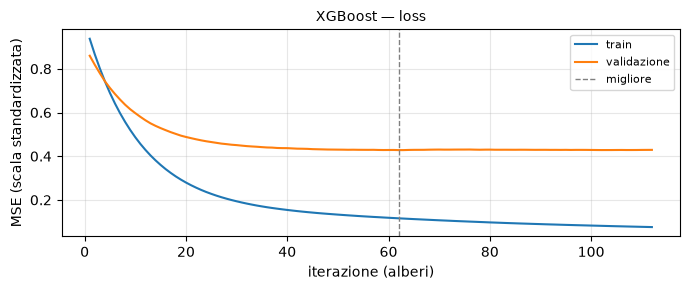

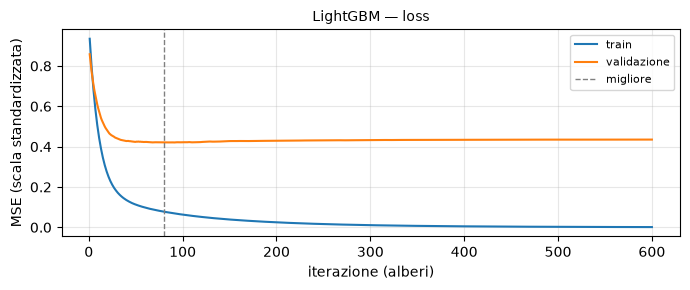

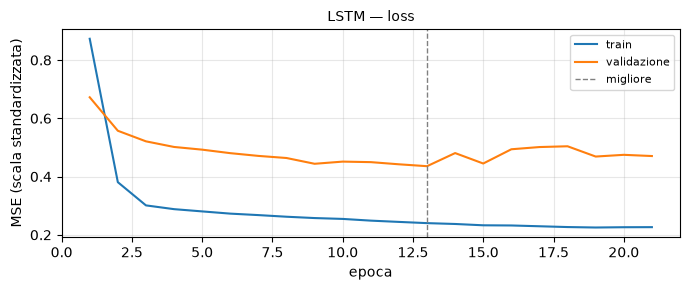

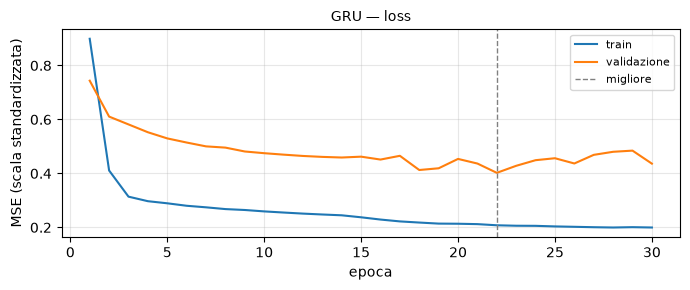

,unità,eseguite,migliore,loss train,loss validazione,secondi
Persistenza,—,0,—,—,—,0.0
Naive 24h,—,0,—,—,—,0.0
Naive 168h,—,0,—,—,—,0.0
XGBoost,iterazione,112,62,0.1158,0.4279,11.0
LightGBM,iterazione,600,80,0.0777,0.4206,64.3
LSTM,epoca,21,13,0.2402,0.4357,12.6
GRU,epoca,30,22,0.2079,0.4022,29.4
Chronos-2,—,0,—,—,—,25.6
Chronos-Bolt,—,0,—,—,—,20.8
TimesFM 2.5,—,0,—,—,—,222.4


In [3]:
addestrati, previsioni, secondi = {}, {}, {}
for nome in MODELLI_DA_ESEGUIRE:
    modello = modelli.crea_modello(nome, PARAMETRI.get(nome), seed=SEED, dispositivo=DISPOSITIVO)
    grafico = None if nome in modelli.SENZA_ADDESTRAMENTO else modelli.GraficoLoss(f'{nome} — loss')
    inizio = time.perf_counter()
    modello.addestra(D, grafico)
    secondi[nome] = time.perf_counter()-inizio
    addestrati[nome] = modello
    previsioni[nome] = modello.prevedi_test(D)   # {'diretta', 'one_step', 'ricorsiva'}

modelli.riepilogo_addestramento(addestrati, secondi).style.format(
    {'loss train': '{:.4f}', 'loss validazione': '{:.4f}', 'secondi': '{:.1f}'}, na_rep='—')

## 3. Metriche sul test

In [4]:
pd.Series(metriche.descrizione(naive='naive 24h'), name='significato').to_frame()

,significato
MAE,errore assoluto medio (kWh)
RMSE,radice dell’errore quadratico medio (kWh)
MAPE %,errore percentuale assoluto medio sui valori r...
sMAPE %,errore percentuale simmetrico
MASE,MAE / MAE del naive 24h sul train (<1 batte il...
Bias,media di (previsto − reale): >0 sovrastima (kWh)
Errore totale %,errore % sul consumo cumulato di ogni finestra...
Copertura 80%,% di valori reali dentro l’intervallo q10–q90 ...
Larghezza 80%,ampiezza media dell’intervallo q10–q90 (kWh; v...


### 3.1 Diretta 48h
A ogni origine (ogni 48 ore) il modello prevede le 48 ore successive in un colpo solo, usando solo i consumi reali fino all'origine.

In [5]:
# 'diretta' e 'ricorsiva' sulle origini di test (n, H); 'breve' e 'one_step' sulle origini orarie (n, ORE_BREVE) e (n, 1)
reale = {'diretta': D.test.target, 'ricorsiva': D.test.target,
         'breve': D.test_orario.target, 'one_step': D.test_orario.target[:, :1]}
tabelle = {v: metriche.tabella({nome: p[v] for nome, p in previsioni.items()}, reale[v], D.scala_mase).sort_values('MASE')
           for v in modelli.VALUTAZIONI}
tabelle_tagli = {v: metriche.tabella({nome: p[v] for nome, p in previsioni.items()}, reale[v], D.scala_mase, t)
                 for v, t in TAGLI.items()}
metriche.formatta(tabelle['diretta'])

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Chronos-2,552.4,742.3,9.32,9.08,0.796,+11.0,3.76,nan,nan
Chronos-Bolt,581.1,780.7,9.89,9.54,0.838,+52.9,3.70,nan,nan
TimesFM 3.0,582.0,773.6,9.85,9.55,0.839,+35.7,3.97,nan,nan
TimesFM 2.5,608.6,807.6,10.41,9.97,0.877,+85.1,4.04,nan,nan
LightGBM,651.4,834.7,10.85,10.68,0.939,-98.0,4.11,nan,nan
XGBoost,655.9,833.0,10.86,10.73,0.946,-127.2,4.27,nan,nan
Naive 24h,705.1,932.3,11.83,11.61,1.017,+45.0,4.90,nan,nan
GRU,902.4,1078.0,14.42,14.65,1.301,-341.3,6.46,nan,nan
LSTM,954.8,1120.8,15.41,15.49,1.377,-282.3,5.59,nan,nan


**Per taglio dell'orizzonte.** Stesse previsioni, metriche sulle sole prime ore di ogni origine:
+1…+6h (le prime ore dopo l'origine), +1…+24h (primo giorno) e +1…+48h (tabella sopra).

In [6]:
for taglio in TAGLI['diretta']:
    display(Markdown(f'**+1…+{taglio}h**'))
    display(metriche.formatta(tabelle_tagli['diretta'].xs(taglio, level='taglio').sort_values('MASE')))

**+1…+6h**

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Chronos-2,391.3,530.2,6.98,6.91,0.564,+3.0,5.35,nan,nan
Chronos-Bolt,426.3,571.8,7.50,7.50,0.615,-40.5,5.63,nan,nan
TimesFM 3.0,431.6,574.6,7.68,7.60,0.622,+16.7,5.90,nan,nan
TimesFM 2.5,439.2,586.8,7.81,7.76,0.633,-31.9,6.03,nan,nan
Persistenza,461.7,598.4,8.31,8.16,0.666,+135.5,6.88,nan,nan
XGBoost,495.8,661.0,8.78,8.71,0.715,-61.3,7.34,nan,nan
LightGBM,497.2,657.3,8.78,8.74,0.717,-51.3,7.38,nan,nan
GRU,672.8,835.6,11.95,11.73,0.970,-54.6,10.71,nan,nan
Naive 24h,728.3,947.0,13.00,13.13,1.050,-107.9,11.06,nan,nan


**+1…+24h**

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Chronos-2,522.7,697.5,8.72,8.55,0.754,+32.1,4.61,nan,nan
TimesFM 3.0,553.7,727.6,9.21,9.02,0.798,+37.7,5.03,nan,nan
Chronos-Bolt,557.5,744.2,9.39,9.10,0.804,+67.0,4.74,nan,nan
TimesFM 2.5,574.8,764.7,9.71,9.37,0.829,+91.3,4.96,nan,nan
LightGBM,632.4,800.0,10.42,10.32,0.912,-82.9,5.27,nan,nan
XGBoost,635.3,800.7,10.43,10.35,0.916,-104.5,5.50,nan,nan
Naive 24h,700.9,917.5,11.66,11.48,1.011,+48.6,6.08,nan,nan
GRU,901.8,1076.2,14.40,14.63,1.300,-331.7,7.21,nan,nan
LSTM,955.8,1117.4,15.40,15.50,1.378,-284.9,6.42,nan,nan


**+1…+48h**

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Chronos-2,552.4,742.3,9.32,9.08,0.796,+11.0,3.76,nan,nan
Chronos-Bolt,581.1,780.7,9.89,9.54,0.838,+52.9,3.70,nan,nan
TimesFM 3.0,582.0,773.6,9.85,9.55,0.839,+35.7,3.97,nan,nan
TimesFM 2.5,608.6,807.6,10.41,9.97,0.877,+85.1,4.04,nan,nan
LightGBM,651.4,834.7,10.85,10.68,0.939,-98.0,4.11,nan,nan
XGBoost,655.9,833.0,10.86,10.73,0.946,-127.2,4.27,nan,nan
Naive 24h,705.1,932.3,11.83,11.61,1.017,+45.0,4.90,nan,nan
GRU,902.4,1078.0,14.42,14.65,1.301,-341.3,6.46,nan,nan
LSTM,954.8,1120.8,15.41,15.49,1.377,-282.3,5.59,nan,nan


### 3.2 Breve termine (+1…+6h)
A ogni ora di test il modello riceve i consumi reali fino all'ora precedente e prevede le 6 ore successive in un colpo.
Sono le prime 6 uscite della stessa previsione diretta, ma con un'origine ogni ora invece che ogni 48 ore:
ogni ora di test viene prevista fino a 6 volte, a distanze diverse. Le origini sono quelle della one-step-ahead,
tranne le ultime 5 ore del test, per cui le 6 ore target uscirebbero dal periodo.

In [7]:
metriche.formatta(tabelle['breve'])

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Chronos-2,459.9,627.0,7.63,7.56,0.663,-27.7,5.80,nan,nan
TimesFM 3.0,471.4,642.1,7.88,7.75,0.680,+15.2,5.96,nan,nan
Chronos-Bolt,488.7,667.0,8.21,8.02,0.705,+25.2,6.29,nan,nan
TimesFM 2.5,496.2,672.8,8.32,8.15,0.715,+18.7,6.37,nan,nan
LightGBM,613.9,777.5,10.18,10.07,0.885,-111.0,7.49,nan,nan
XGBoost,615.2,776.6,10.20,10.09,0.887,-123.3,7.62,nan,nan
Naive 24h,671.7,878.9,11.23,11.09,0.968,+15.6,8.66,nan,nan
Persistenza,856.0,1170.5,14.12,13.93,1.234,+3.7,12.45,nan,nan
GRU,906.3,1079.0,14.31,14.72,1.307,-393.2,11.81,nan,nan


**Per taglio**: +1h (uguale alla one-step-ahead), +1…+3h e +1…+6h.

In [8]:
for taglio in TAGLI['breve']:
    display(Markdown(f'**+1…+{taglio}h**'))
    display(metriche.formatta(tabelle_tagli['breve'].xs(taglio, level='taglio').sort_values('MASE')))

**+1…+1h**

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
TimesFM 3.0,330.2,447.9,5.34,5.30,0.476,+2.4,5.34,nan,nan
Chronos-2,333.8,457.0,5.39,5.38,0.481,-19.3,5.39,nan,nan
TimesFM 2.5,341.0,460.8,5.53,5.49,0.492,-4.4,5.53,nan,nan
Chronos-Bolt,343.4,463.4,5.57,5.54,0.495,-15.4,5.57,nan,nan
Persistenza,417.0,582.8,6.75,6.71,0.601,+1.3,6.75,nan,nan
LightGBM,446.2,576.8,7.20,7.27,0.643,-134.6,7.20,nan,nan
XGBoost,468.3,597.6,7.57,7.63,0.675,-145.1,7.57,nan,nan
Naive 24h,672.0,879.3,11.23,11.09,0.969,+18.0,11.23,nan,nan
GRU,866.7,1034.0,13.62,14.03,1.250,-390.5,13.62,nan,nan


**+1…+3h**

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Chronos-2,409.3,561.5,6.72,6.68,0.590,-24.6,5.76,nan,nan
TimesFM 3.0,411.8,563.9,6.81,6.72,0.594,+19.2,5.82,nan,nan
Chronos-Bolt,430.8,588.1,7.14,7.03,0.621,+8.9,6.15,nan,nan
TimesFM 2.5,435.8,591.9,7.21,7.11,0.628,+3.6,6.23,nan,nan
LightGBM,566.4,720.5,9.31,9.29,0.817,-138.5,8.24,nan,nan
XGBoost,568.8,719.4,9.35,9.32,0.820,-139.8,8.33,nan,nan
Persistenza,623.2,888.0,10.24,10.13,0.899,+2.4,9.40,nan,nan
Naive 24h,671.8,879.1,11.23,11.09,0.969,+17.0,9.95,nan,nan
GRU,887.7,1057.6,13.98,14.39,1.280,-393.3,12.96,nan,nan


**+1…+6h**

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Chronos-2,459.9,627.0,7.63,7.56,0.663,-27.7,5.80,nan,nan
TimesFM 3.0,471.4,642.1,7.88,7.75,0.680,+15.2,5.96,nan,nan
Chronos-Bolt,488.7,667.0,8.21,8.02,0.705,+25.2,6.29,nan,nan
TimesFM 2.5,496.2,672.8,8.32,8.15,0.715,+18.7,6.37,nan,nan
LightGBM,613.9,777.5,10.18,10.07,0.885,-111.0,7.49,nan,nan
XGBoost,615.2,776.6,10.20,10.09,0.887,-123.3,7.62,nan,nan
Naive 24h,671.7,878.9,11.23,11.09,0.968,+15.6,8.66,nan,nan
Persistenza,856.0,1170.5,14.12,13.93,1.234,+3.7,12.45,nan,nan
GRU,906.3,1079.0,14.31,14.72,1.307,-393.2,11.81,nan,nan


**MAE per ora dell'orizzonte** (kWh), mediato sulle origini orarie: quanto cresce l'errore allontanandosi dall'origine.

In [9]:
pd.DataFrame({nome: metriche.mae_per_orizzonte(reale['breve'], p['breve']) for nome, p in previsioni.items()},
             index=pd.Index(range(1, ORE_BREVE+1), name='ora')).T.sort_values(ORE_BREVE).style.format('{:.1f}')

ora,1,2,3,4,5,6
Chronos-2,333.8,419.6,474.5,498.2,511.9,521.6
TimesFM 3.0,330.2,424.2,480.9,514.0,532.5,546.6
Chronos-Bolt,343.4,443.0,506.1,534.6,549.3,556.0
TimesFM 2.5,341.0,448.8,517.5,546.0,556.9,566.8
Naive 24h,672.0,671.5,672.0,671.9,671.4,671.1
XGBoost,468.3,628.3,609.8,633.4,647.8,703.8
LightGBM,446.2,632.0,621.2,622.8,655.3,705.9
GRU,866.7,889.8,906.6,918.5,925.9,930.0
Naive 168h,1005.2,1005.2,1005.7,1006.8,1007.5,1008.0
LSTM,911.7,943.1,968.9,989.9,1006.9,1020.8


### 3.3 One-step-ahead (+1h)
A ogni ora di test il modello riceve i consumi reali fino all'ora precedente e si valuta solo la previsione dell'ora successiva.
È il compito più facile: misura la previsione a un'ora, non a due giorni.

In [10]:
metriche.formatta(tabelle['one_step'])

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
TimesFM 3.0,330.2,447.9,5.34,5.30,0.476,+2.4,5.34,nan,nan
Chronos-2,333.8,457.0,5.39,5.38,0.481,-19.3,5.39,nan,nan
TimesFM 2.5,341.0,460.8,5.53,5.49,0.492,-4.4,5.53,nan,nan
Chronos-Bolt,343.4,463.4,5.57,5.54,0.495,-15.4,5.57,nan,nan
Persistenza,417.0,582.8,6.75,6.71,0.601,+1.3,6.75,nan,nan
LightGBM,446.2,576.8,7.20,7.27,0.643,-134.6,7.20,nan,nan
XGBoost,468.3,597.6,7.57,7.63,0.675,-145.1,7.57,nan,nan
Naive 24h,672.0,879.3,11.23,11.09,0.969,+18.0,11.23,nan,nan
GRU,866.7,1034.0,13.62,14.03,1.250,-390.5,13.62,nan,nan


### 3.4 Autoregressiva 48h
A ogni origine (ogni 48 ore) il modello prevede solo +1h, inserisce la propria previsione nello storico come se fosse un dato reale e ripete 48 volte.
Dopo la prima ora non vede più consumi reali, quindi gli errori possono accumularsi.
Si usa l'uscita +1h degli stessi modelli addestrati: per LightGBM è il regressore dell'orizzonte 1, per le reti la stessa testa valutata a h = 1.
Per i preaddestrati si chiede +1h, la previsione si aggiunge in coda al contesto e si ripete.
Per i baseline coincide con la diretta, perché copiano valori già noti.

In [11]:
metriche.formatta(tabelle['ricorsiva'])

,MAE,RMSE,MAPE %,sMAPE %,MASE,Bias,Errore totale %,Copertura 80%,Larghezza 80%
modello,,,,,,,,,
Chronos-2,578.0,773.3,9.76,9.47,0.833,+64.3,4.13,nan,nan
TimesFM 3.0,586.5,787.9,9.91,9.62,0.846,+47.1,4.45,nan,nan
TimesFM 2.5,622.5,823.8,10.46,10.22,0.898,-2.5,4.19,nan,nan
Chronos-Bolt,637.1,855.7,10.66,10.36,0.919,+30.3,4.38,nan,nan
Naive 24h,705.1,932.3,11.83,11.61,1.017,+45.0,4.90,nan,nan
LightGBM,744.4,928.2,12.03,12.08,1.073,-251.6,5.60,nan,nan
XGBoost,771.6,943.7,12.32,12.48,1.113,-309.9,6.13,nan,nan
GRU,959.7,1149.1,15.10,15.60,1.384,-431.7,7.63,nan,nan
LSTM,982.8,1154.2,15.61,15.97,1.417,-385.5,6.74,nan,nan


## 4. Salvataggio (opzionale)
Con `SALVA_RISULTATI = True` metriche, riepilogo e configurazione vanno in una nuova cartella `risultati/<utente>_<data>`.

In [12]:
if SALVA_RISULTATI:
    cartella = Path('risultati')/f"{UTENTE}_{pd.Timestamp.now():%Y%m%d_%H%M%S}"
    cartella.mkdir(parents=True)
    for v, t in tabelle.items():
        t.to_csv(cartella/f'metriche_{v}.csv')
    for v, t in tabelle_tagli.items():
        t.to_csv(cartella/f'metriche_{v}_tagli.csv')
    modelli.riepilogo_addestramento(addestrati, secondi).to_csv(cartella/'addestramento.csv')
    (cartella/'configurazione.json').write_text(json.dumps(dict(
        utente=UTENTE, periodi=PERIODI, horizon=HORIZON, lookback=LOOKBACK, ore_breve=ORE_BREVE,
        tagli=TAGLI, seed=SEED,
        modelli=MODELLI_DA_ESEGUIRE, parametri={n: {**modelli.PARAMETRI.get(n, {}), **PARAMETRI.get(n, {})}
                                                 for n in MODELLI_DA_ESEGUIRE}), indent=2))
    print('Salvato in', cartella)

Salvato in risultati/U141_20261031_130627
